# Multiple Time Series dan Seasonal Plot

Nama: Jeany

## Import Library dan Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

TICKERS = ['BBCA', 'BBRI', 'BMRI', 'BBNI']
NAMA_BANK = {
    'BBCA': 'Bank Central Asia',
    'BBRI': 'Bank Rakyat Indonesia',
    'BMRI': 'Bank Mandiri',
    'BBNI': 'Bank Negara Indonesia',
}
WARNA = {'BBCA': '#2a78d6', 'BBRI': '#eb6834', 'BMRI': '#1baf7a', 'BBNI': '#eda100'}

# lokasi folder dataset (root repo / folder kerja), kalau tidak ada ambil dari GitHub
if Path('dataset').is_dir():
    ROOT = Path('.')
elif Path('../dataset').is_dir():
    ROOT = Path('..')
else:
    ROOT = None
DATA_DIR = f'{ROOT}/dataset' if ROOT else 'https://raw.githubusercontent.com/aprilianza/Midterm_DataVisualization/main/dataset'
FIG_DIR = (ROOT or Path('.')) / 'figures'
FIG_DIR.mkdir(exist_ok=True)

list_df = []
for t in TICKERS:
    df = pd.read_csv(f'{DATA_DIR}/{t}.JK_10_years.csv')
    df['Date'] = pd.to_datetime(df['Date'], utc=True).dt.tz_localize(None)
    df['Ticker'] = t
    list_df.append(df.sort_values('Date'))

df_all = pd.concat(list_df, ignore_index=True)
df_all = df_all[['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]
df_all = df_all.drop_duplicates(['Ticker', 'Date'])

# baris volume 0 dengan harga datar = hari libur bursa, dibuang untuk semua bank
libur = ((df_all['Volume'] == 0) & (df_all['Open'] == df_all['Close'])
         & (df_all['High'] == df_all['Close']) & (df_all['Low'] == df_all['Close']))
HARI_DIBUANG = pd.DatetimeIndex(df_all.loc[libur, 'Date'].unique()).sort_values()
df_all = df_all[~df_all['Date'].isin(HARI_DIBUANG)].reset_index(drop=True)

adj_wide = df_all.pivot(index='Date', columns='Ticker', values='Adj Close')[TICKERS]
vol_wide = df_all.pivot(index='Date', columns='Ticker', values='Volume')[TICKERS]

plt.rcParams.update({
    'figure.figsize': (12, 5),
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e6e5e0',
    'legend.frameon': False,
})


def simpan_fig(fig, nama):
    fig.savefig(FIG_DIR / f'{nama}.png')


def format_tanggal(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


print('Jumlah baris df_all :', len(df_all))
print('Rentang tanggal     :', df_all['Date'].min().date(), 's.d.', df_all['Date'].max().date())
print('Hari libur dibuang  :', len(HARI_DIBUANG))

Jumlah baris df_all : 9616
Rentang tanggal     : 2014-12-08 s.d. 2024-12-03
Hari libur dibuang  : 69


## Multiple Time Series

Untuk membandingkan pertumbuhan harga keempat bank, harga Adj Close diubah menjadi **indeks dengan minggu pertama = 100**, sehingga semua bank mulai dari titik yang sama meskipun harga nominalnya berbeda. Data harian diubah menjadi mingguan (harga penutupan terakhir tiap minggu) agar garis lebih bersih dan tren jangka panjang lebih mudah dibandingkan. Nama bank ditulis langsung di ujung garis (*direct labeling*) sebagai pengganti legend.


In [2]:
# harga penutupan terakhir tiap minggu; minggu tanpa hari bursa (libur Lebaran) dibuang
c_mingguan = adj_wide.resample('W-FRI').last().dropna()

# indeks harga: minggu pertama = 100
c_indeks = c_mingguan / c_mingguan.iloc[0] * 100
c_akhir = c_indeks.iloc[-1].sort_values(ascending=False)
c_akhir.round(1).to_frame('Indeks akhir')


,Indeks akhir
Ticker,
BBCA,454.9
BMRI,349.8
BBRI,287.6
BBNI,209.0


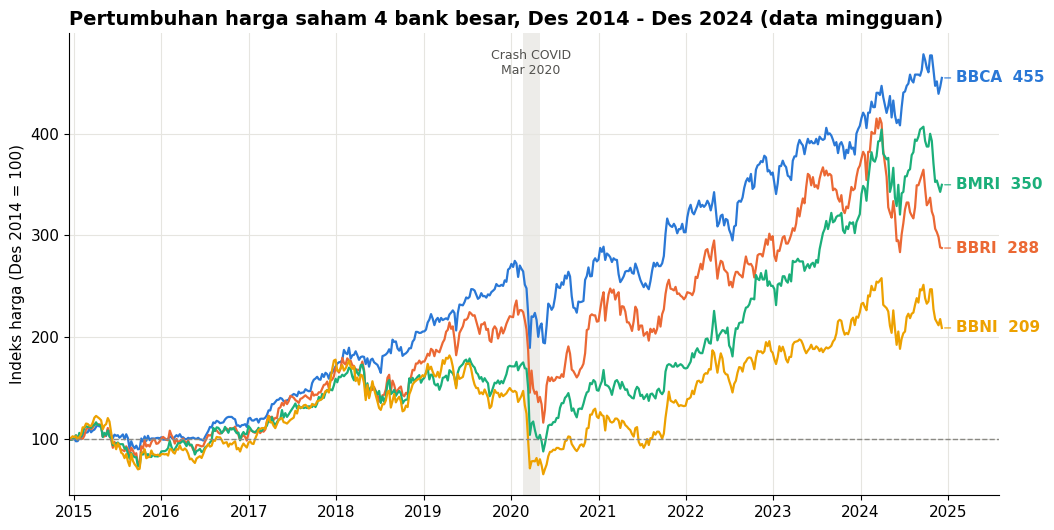

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
for t in TICKERS:
    ax.plot(c_indeks.index, c_indeks[t], color=WARNA[t], lw=1.6)
ax.axhline(100, color='#8a8984', lw=1, ls='--')

# direct label di ujung kanan garis; label digeser ke bawah bila terlalu dekat dengan label di atasnya
c_jarak = (c_indeks.max().max() - c_indeks.min().min()) * 0.05
c_x_akhir = c_indeks.index[-1]
c_y_label = []
for t, v in c_akhir.items():
    y = v if not c_y_label or c_y_label[-1] - v >= c_jarak else c_y_label[-1] - c_jarak
    c_y_label.append(y)
    ax.annotate(f'{t}  {v:.0f}', xy=(c_x_akhir, v), xytext=(c_x_akhir + pd.Timedelta(days=60), y),
                color=WARNA[t], fontsize=11, fontweight='bold', va='center',
                arrowprops=dict(arrowstyle='-', color=WARNA[t], lw=0.8))

# penanda crash COVID-19
ax.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-04-30'), color='#e6e5e0', alpha=0.7, lw=0)
ax.text(pd.Timestamp('2020-03-25'), ax.get_ylim()[1] * 0.97, 'Crash COVID\nMar 2020',
        ha='center', va='top', fontsize=9, color='#52514e')

format_tanggal(ax)
ax.set_xlim(c_indeks.index[0], c_x_akhir + pd.Timedelta(days=240))
ax.set_ylabel('Indeks harga (Des 2014 = 100)')
ax.set_title('Pertumbuhan harga saham 4 bank besar, Des 2014 - Des 2024 (data mingguan)')
simpan_fig(fig, '03_multiple_time_series')
plt.show()


**Insight:** Dalam 10 tahun, BBCA tumbuh paling tinggi (indeks ±455, naik sekitar 4,5×), disusul BMRI (±350), BBRI (±288), dan BBNI (±209). Keempat bank bergerak hampir seragam pada 2015–2017, lalu mulai terpisah sejak 2018. Saat crash COVID Maret 2020 semua bank anjlok bersamaan, bahkan BBNI sempat turun di bawah harga awal 2014 (indeks 71) dan BMRI kembali ke level harga awal (indeks 99,7). BBCA paling cepat pulih ke level sebelum pandemi (Des 2020), dibanding BBRI (Jan 2021) serta BMRI dan BBNI (Jan–Feb 2022).


##  Seasonal Heatmap

Untuk melihat pola musiman, dihitung **return bulanan** tiap bank, yaitu perubahan harga dari akhir bulan sebelumnya ke akhir bulan tersebut. Return dari 2015–2024 lalu dirata-ratakan per bulan kalender (Jan–Des), sehingga tiap kotak menunjukkan rata-rata return bank tersebut pada bulan itu selama 2015–2024. Biru berarti rata-rata naik, merah berarti rata-rata turun. Desember 2014 tidak dipakai karena tidak punya bulan pembanding, dan Desember 2024 tidak dipakai karena hanya berisi 2 hari bursa. Dengan demikian Januari–November dirata-ratakan dari 10 nilai, sedangkan Desember dari 9 nilai (2015–2023).


In [7]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# return bulanan (%): harga akhir bulan dibanding akhir bulan sebelumnya
c_return = adj_wide.resample('ME').last().pct_change() * 100
# Des 2014 tidak punya bulan pembanding, Des 2024 hanya berisi 2 hari bursa
c_return = c_return.loc['2015-01':'2024-11']

# baris = bank, kolom = bulan kalender
c_bulan = c_return.index.month
c_rata = c_return.groupby(c_bulan).mean().T
c_rata.round(1)


Date,1,2,3,4,5,6,7,8,9,10,11,12
Ticker,,,,,,,,,,,,
BBCA,1.3,1.8,-0.1,0.2,-0.5,0.8,3.3,3.2,-0.3,2.3,0.7,4.2
BBRI,0.1,4.5,0.4,-4.3,1.2,-1.6,2.0,3.4,-2.9,4.2,2.7,5.0
BMRI,2.2,1.3,2.0,-2.0,-2.2,1.1,3.7,3.0,-2.9,5.6,0.3,3.9
BBNI,-0.2,3.8,-1.1,-2.0,-2.3,-2.3,1.0,5.2,-2.7,5.4,4.8,4.3


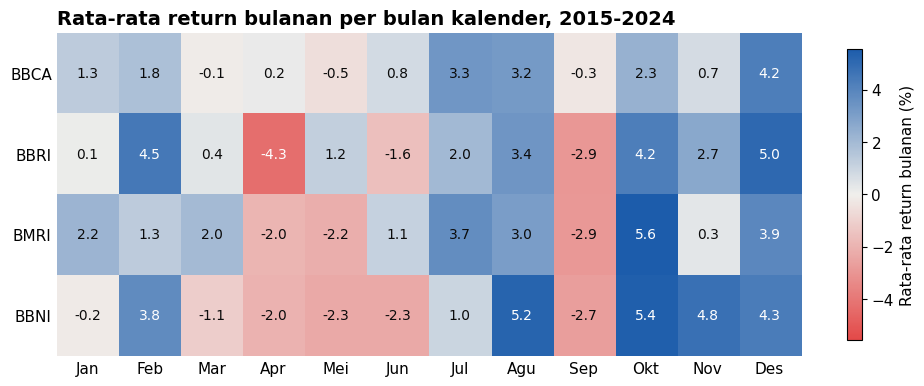

In [8]:
BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
# merah = turun, abu-abu terang = 0, biru = naik
c_cmap = LinearSegmentedColormap.from_list('c_merah_biru', ['#e34948', '#f0efec', '#1c5cab'])
c_batas = np.abs(c_rata.values).max()
c_norm = TwoSlopeNorm(vcenter=0, vmin=-c_batas, vmax=c_batas)

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(c_rata.values, cmap=c_cmap, norm=c_norm, aspect='auto')
ax.set_xticks(range(12), BULAN)
ax.set_yticks(range(len(TICKERS)), c_rata.index)
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)

# tulis nilai rata-rata return di tiap kotak
for i in range(c_rata.shape[0]):
    for j in range(c_rata.shape[1]):
        v = c_rata.iat[i, j]
        warna_teks = 'white' if abs(c_norm(v) - 0.5) > 0.33 else '#0b0b0b'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=10, color=warna_teks)

fig.colorbar(im, ax=ax, shrink=0.9, label='Rata-rata return bulanan (%)')
ax.set_title('Rata-rata return bulanan per bulan kalender, 2015-2024')
simpan_fig(fig, '04_seasonal_heatmap')
plt.show()


**Insight:** Desember menjadi bulan dengan rata-rata return tertinggi bagi keempat bank (+3,9% hingga +5,0%), dan Oktober juga kuat, terutama untuk BMRI (+5,6%), BBNI (+5,4%), dan BBRI (+4,2%). Sebaliknya, September negatif di semua bank (−0,3% hingga −2,9%), dan April–Juni rata-rata negatif pada BBRI, BMRI, dan BBNI, sedangkan BBCA bergerak di sekitar nol pada bulan-bulan tersebut (−0,5% hingga +0,8%). BBCA memiliki warna paling pucat, artinya pergerakan bulanannya paling stabil dibanding tiga bank lain. Karena setiap kotak hanya rata-rata dari 9–10 nilai, pola ini bersifat kecenderungan dan belum tentu berulang pada tahun-tahun berikutnya.